# Exploratory Data Analysis (EDA)

## Customer Churn Prediction

### Objectives
- Analyze numerical features
- Analyze categorical features
- Study customer churn distribution
- Identify relationships between features and churn
- Detect outliers and unusual patterns
- Extract business insights

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv(
    "../data/raw/Telco-Customer-Churn.csv"
)

print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [3]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [4]:
numeric_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical Features:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [5]:
for col in df.columns:
    print(
        f"{col}: {df[col].nunique()} unique values"
    )

customerID: 7043 unique values
gender: 2 unique values
SeniorCitizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
tenure: 73 unique values
PhoneService: 2 unique values
MultipleLines: 3 unique values
InternetService: 3 unique values
OnlineSecurity: 3 unique values
OnlineBackup: 3 unique values
DeviceProtection: 3 unique values
TechSupport: 3 unique values
StreamingTV: 3 unique values
StreamingMovies: 3 unique values
Contract: 3 unique values
PaperlessBilling: 2 unique values
PaymentMethod: 4 unique values
MonthlyCharges: 1585 unique values
TotalCharges: 6531 unique values
Churn: 2 unique values


In [6]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
churn_rates = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
)

print(churn_rates
     )

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:
churn_summary = pd.DataFrame({
    "Count": churn_counts,
    "Percentage": churn_rates
})

churn_summary

,Count,Percentage
Churn,,
No,5174,73.463013
Yes,1869,26.536987


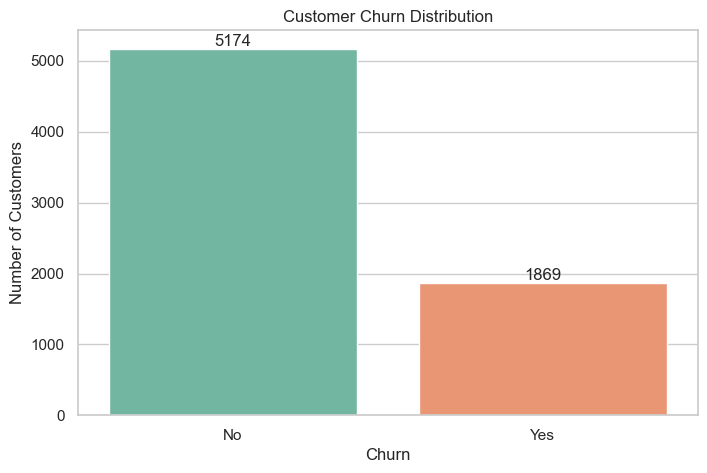

In [9]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [10]:
df[["tenure", "MonthlyCharges",
    "SeniorCitizen"]].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00


In [11]:
total_charges = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

total_charges.describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

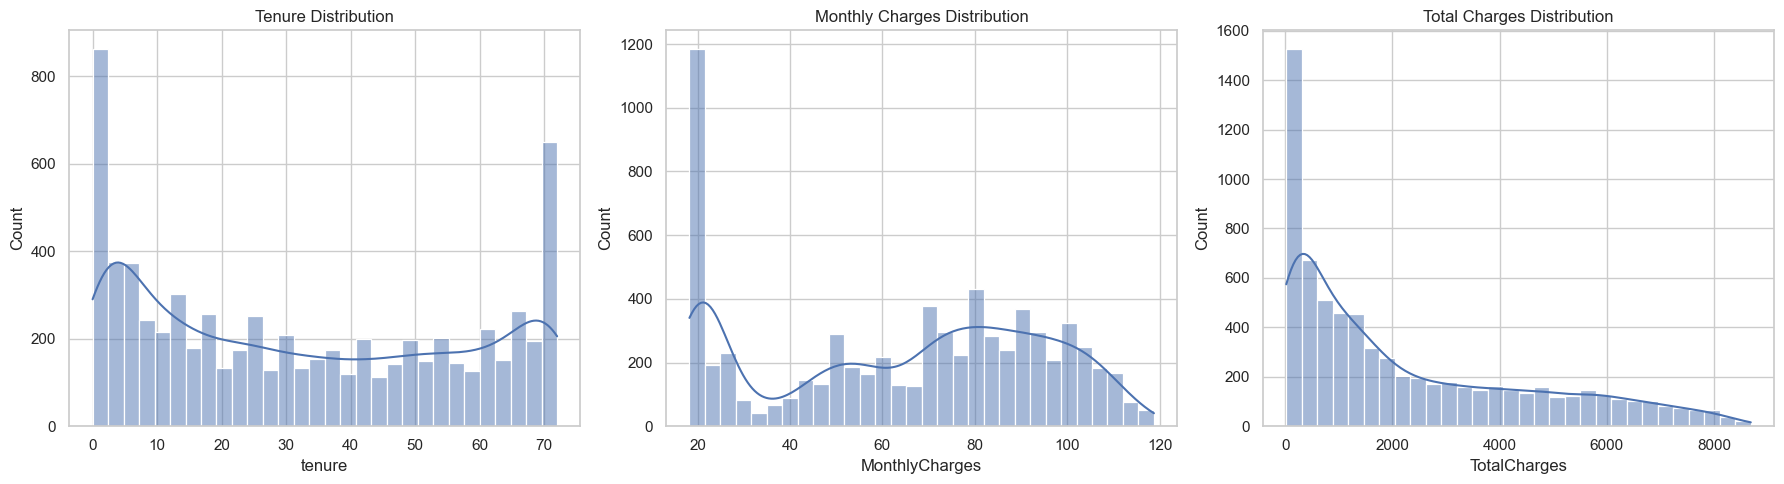

In [12]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

sns.histplot(
    df["tenure"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Tenure Distribution")

sns.histplot(
    df["MonthlyCharges"],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Monthly Charges Distribution")

sns.histplot(
    total_charges.dropna(),
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Total Charges Distribution")

plt.tight_layout()
plt.show()

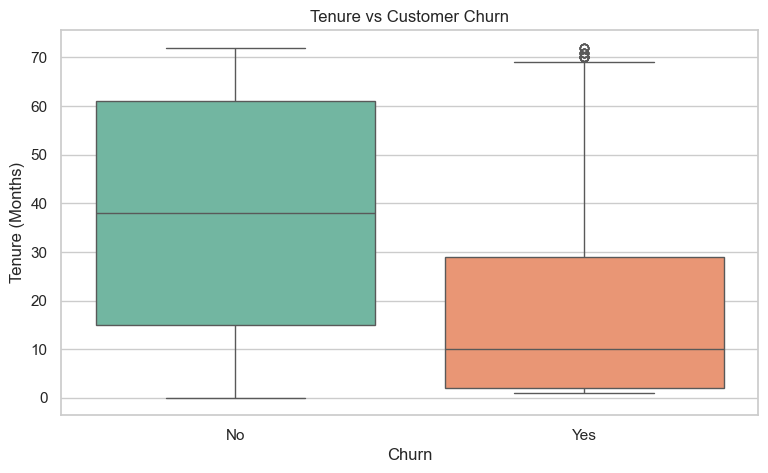

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

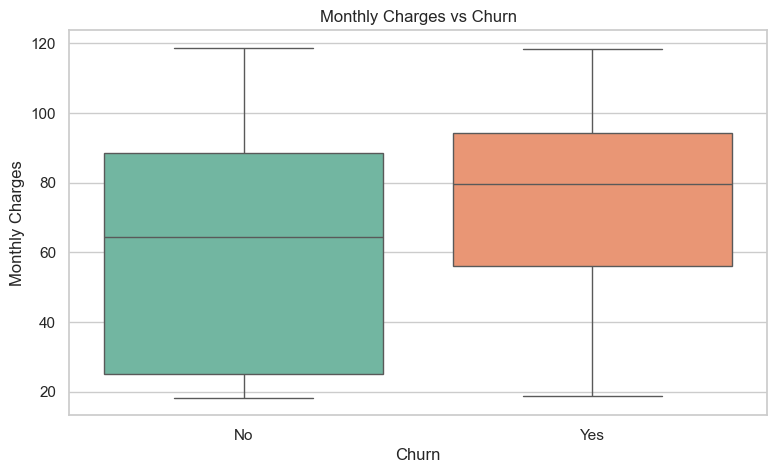

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

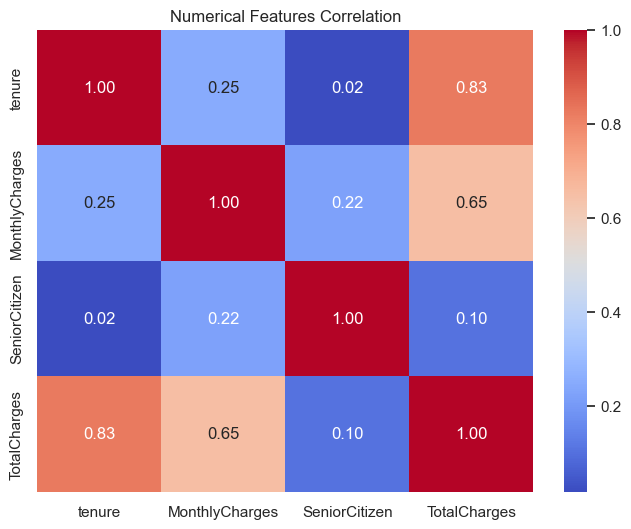

In [15]:
correlation_data = df[
    ["tenure", "MonthlyCharges", "SeniorCitizen"]
].copy()

correlation_data["TotalCharges"] = total_charges

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Features Correlation")

plt.show()

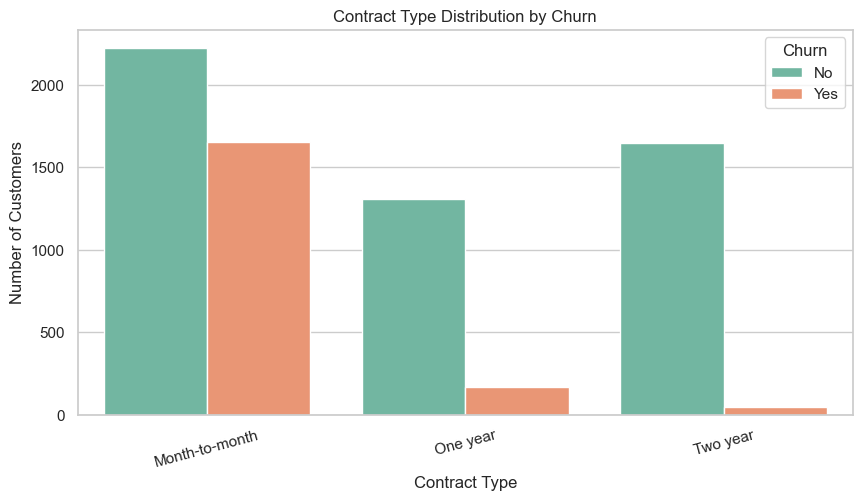

In [16]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Contract Type Distribution by Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.legend(title="Churn")

plt.show()

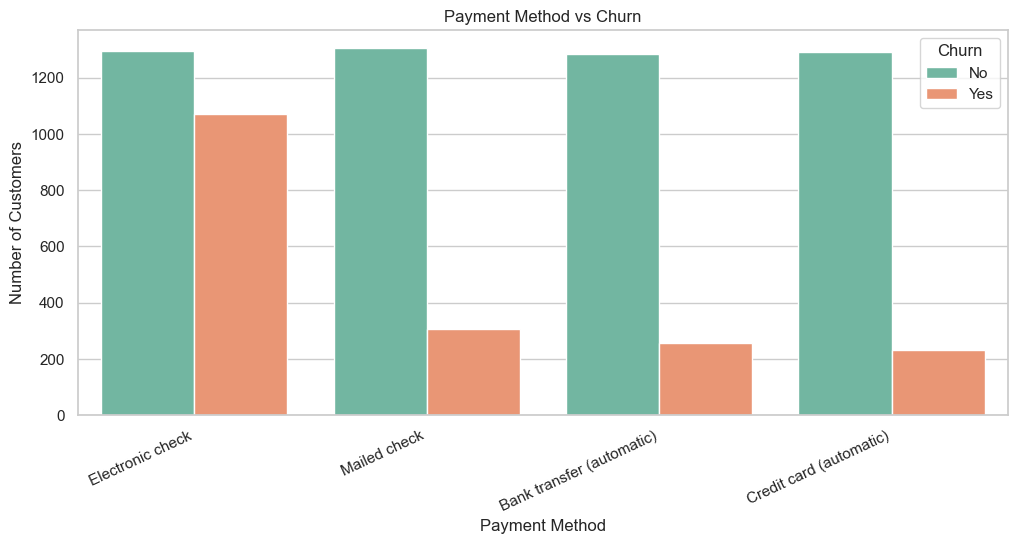

In [17]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn",
    palette="Set2"
)

plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25, ha="right")

plt.show()

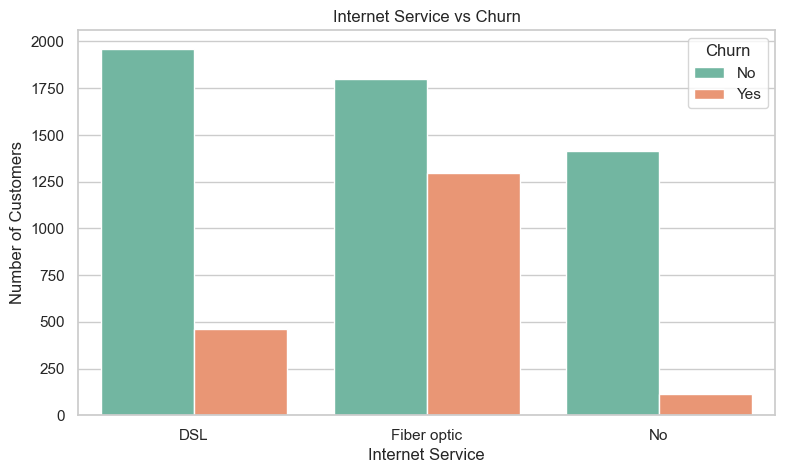

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    palette="Set2"
)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


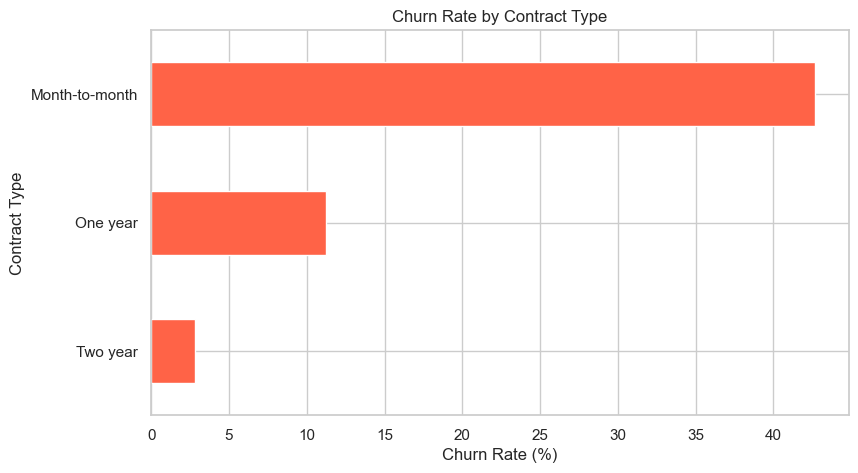

In [20]:
contract_churn["Yes"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="tomato"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")

plt.show()


Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


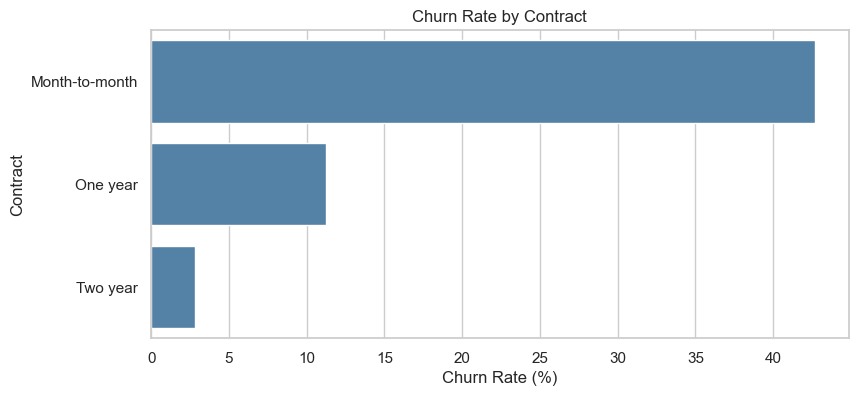


Churn Rate by PaymentMethod:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


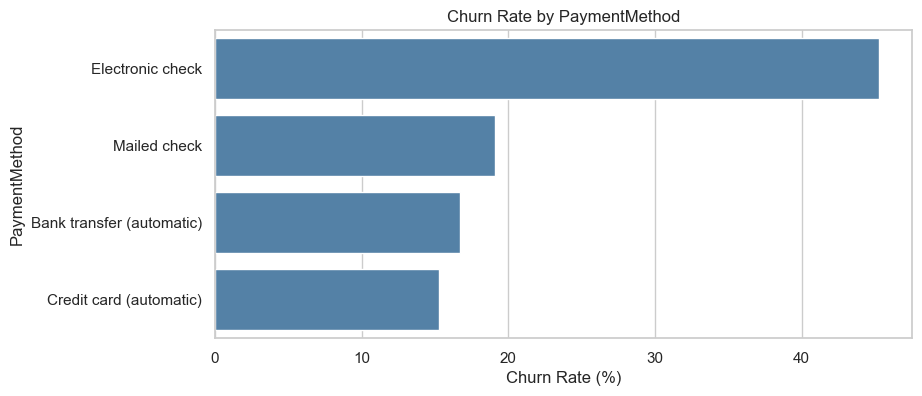


Churn Rate by InternetService:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


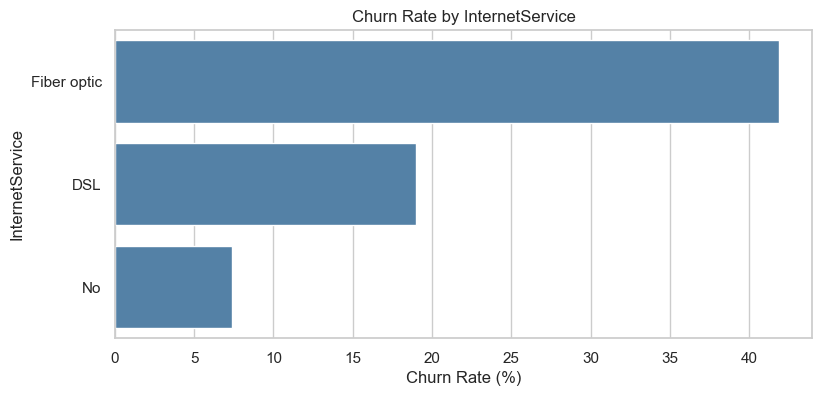


Churn Rate by OnlineSecurity:
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64


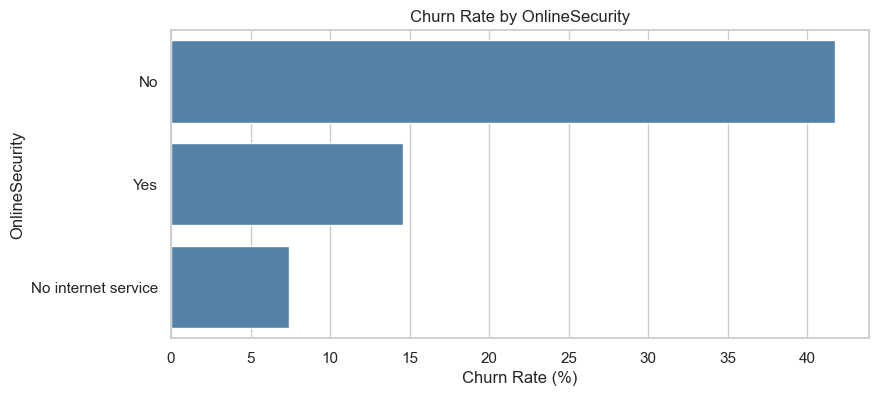


Churn Rate by TechSupport:
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


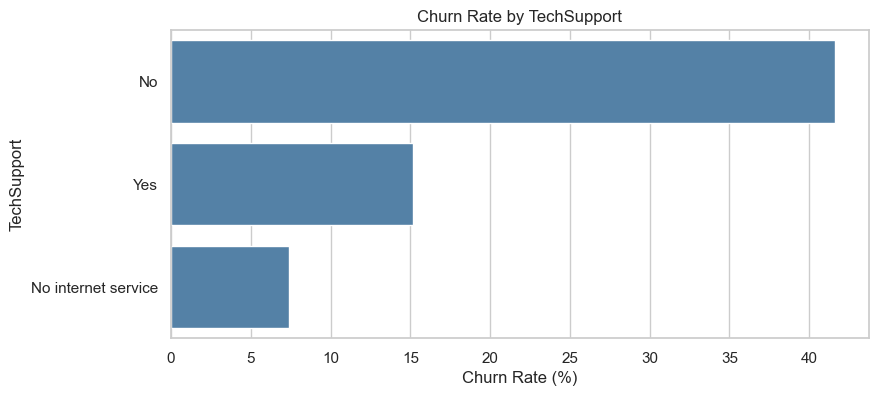


Churn Rate by PaperlessBilling:
PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


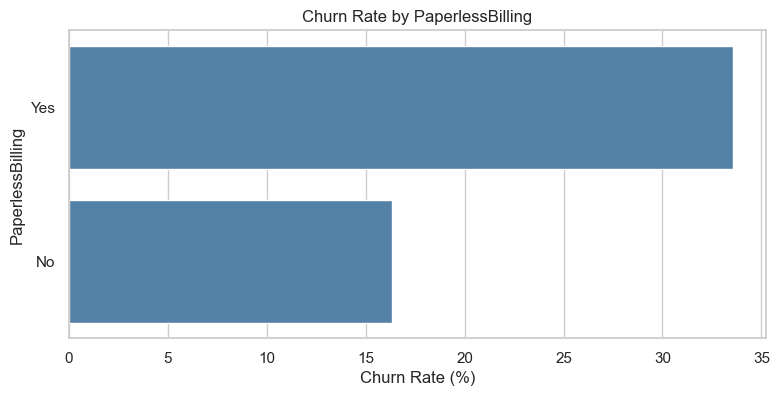


Churn Rate by Partner:
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64


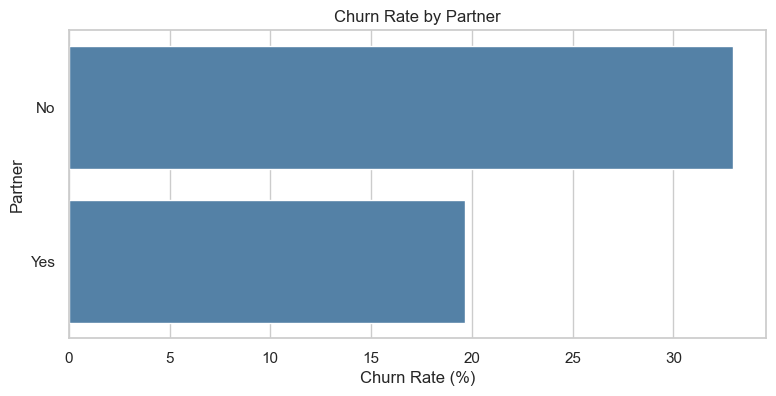


Churn Rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


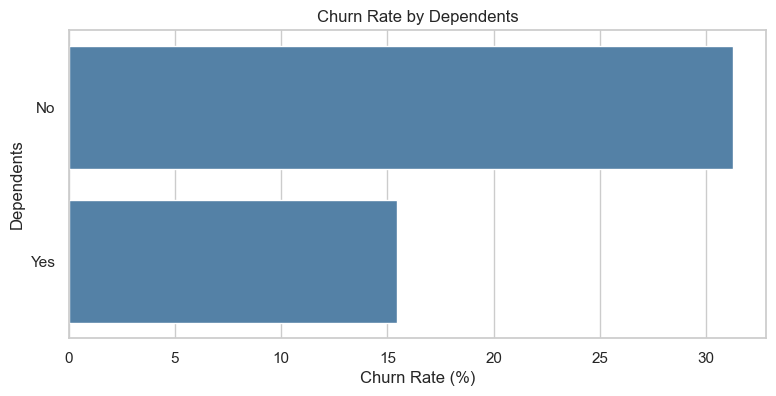

In [21]:
categorical_cols = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling",
    "Partner",
    "Dependents"
]

for col in categorical_cols:

    churn_rate = (
        df.groupby(col, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn Rate by {col}:")
    print(churn_rate.round(2))

    plt.figure(figsize=(9, 4))

    sns.barplot(
        x=churn_rate.values,
        y=churn_rate.index,
        color="steelblue"
    )

    plt.title(f"Churn Rate by {col}")
    plt.xlabel("Churn Rate (%)")
    plt.ylabel(col)

    plt.show()

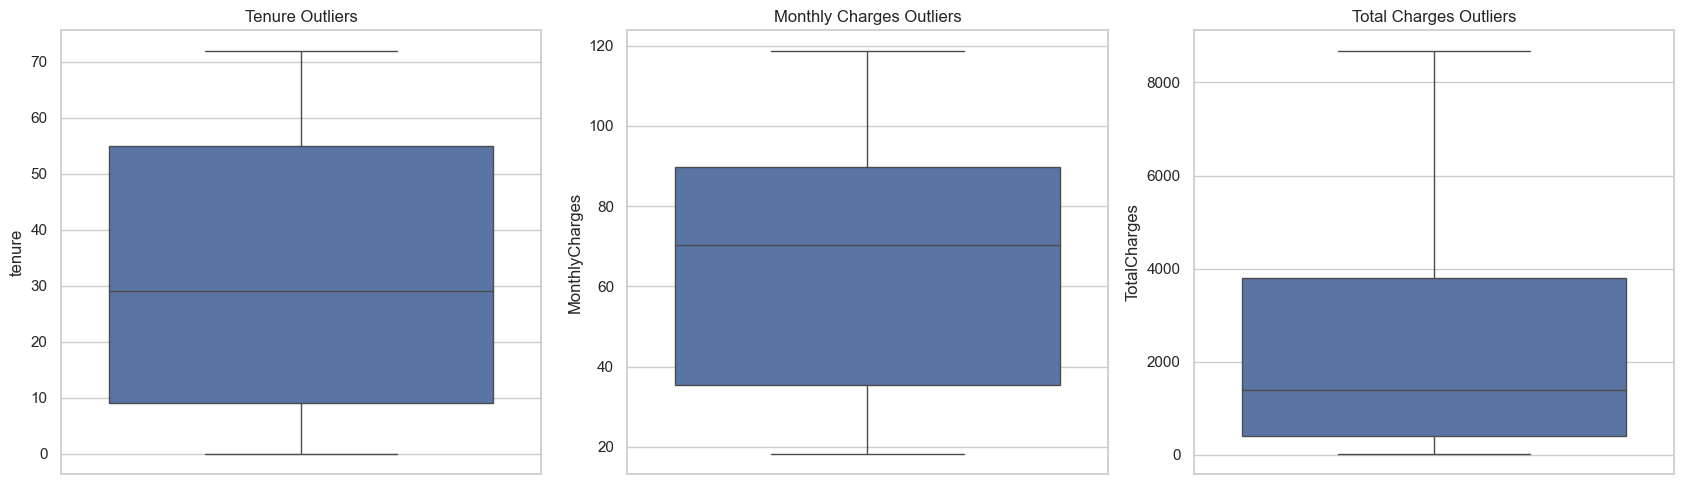

In [22]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

sns.boxplot(y=df["tenure"], ax=axes[0])
axes[0].set_title("Tenure Outliers")

sns.boxplot(y=df["MonthlyCharges"], ax=axes[1])
axes[1].set_title("Monthly Charges Outliers")

sns.boxplot(
    y=total_charges.dropna(),
    ax=axes[2]
)
axes[2].set_title("Total Charges Outliers")

plt.tight_layout()
plt.show()

In [23]:
def detect_outliers_iqr(series):

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower_bound) |
        (series > upper_bound)
    ]

    return {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    }

In [24]:
for col in ["tenure", "MonthlyCharges"]:

    print(f"\n{col}")

    result = detect_outliers_iqr(df[col])

    for key, value in result.items():
        print(f"{key}: {value}")


tenure
Q1: 9.0
Q3: 55.0
IQR: 46.0
Lower Bound: -60.0
Upper Bound: 124.0
Outlier Count: 0

MonthlyCharges
Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Outlier Count: 0


In [25]:
detect_outliers_iqr(total_charges.dropna())

{'Q1': 401.45,
 'Q3': 3794.7375,
 'IQR': 3393.2875000000004,
 'Lower Bound': -4688.481250000001,
 'Upper Bound': 8884.66875,
 'Outlier Count': 0}

In [25]:
df_eda = df.copy()

df_eda["TenureGroup"] = pd.cut(
    df_eda["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

In [26]:
tenure_churn = (
    df_eda.groupby(
        "TenureGroup",
        observed=True
    )["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(tenure_churn.round(2))

TenureGroup
0-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Churn, dtype: float64


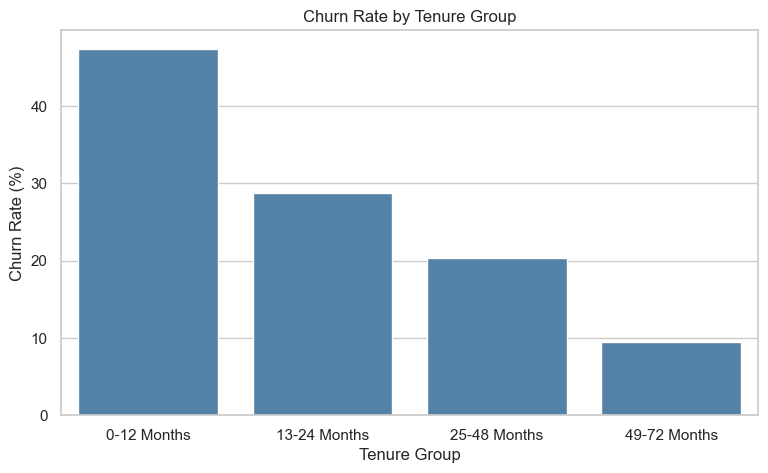

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index.astype(str),
    y=tenure_churn.values,
    color="steelblue"
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

In [28]:
overall_churn_rate = (
    df["Churn"].eq("Yes").mean() * 100
)

contract_rate = (
    df.groupby("Contract", observed=True)["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
)

internet_rate = (
    df.groupby("InternetService", observed=True)["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
)

payment_rate = (
    df.groupby("PaymentMethod", observed=True)["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
)

print("Overall Churn Rate:",
      round(overall_churn_rate, 2), "%")

print("\nChurn by Contract:")
print(contract_rate.round(2))

print("\nChurn by Internet Service:")
print(internet_rate.round(2))

print("\nChurn by Payment Method:")
print(payment_rate.round(2))

Overall Churn Rate: 26.54 %

Churn by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

Churn by Payment Method:
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64


In [29]:
business_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Overall Churn Rate",
        "Average Tenure",
        "Average Monthly Charges"
    ],

    "Value": [
        len(df),
        (df["Churn"] == "Yes").sum(),
        (df["Churn"] == "No").sum(),
        round(overall_churn_rate, 2),
        round(df["tenure"].mean(), 2),
        round(df["MonthlyCharges"].mean(), 2)
    ]
})

business_summary

,Metric,Value
0,Total Customers,7043.00
1,Churned Customers,1869.00
2,Retained Customers,5174.00
3,Overall Churn Rate,26.54
4,Average Tenure,32.37
5,Average Monthly Charges,64.76


## Business Insights

1. Customer churn distribution:
   [Write your findings]

2. Contract type:
   [Write your findings]

3. Tenure:
   [Write your findings]

4. Monthly charges:
   [Write your findings]

5. Internet service:
   [Write your findings]

6. Payment method:
   [Write your findings]

## EDA Conclusion

The EDA process helped identify important
patterns associated with customer churn.

These findings will guide the next steps
in data preprocessing and feature engineering.

In [30]:
import pandas as pd
import numpy as np
from pathlib import Path

Path("../reports").mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True), errors="coerce"
)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# 1) نرخ کلی ریزش
print(f"نرخ کلی ریزش: {df['Churn'].mean():.2%}  ({int(df['Churn'].sum())} از {len(df)})")

# 2) ریزش بر اساس Contract
print(df.groupby("Contract")["Churn"].agg(churn_rate="mean", customers="count")
        .assign(churn_rate=lambda x: (x["churn_rate"]*100).round(2)))

# 3) ریزش بر اساس گروه tenure
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1,6,12,24,48,72],
                            labels=["0-6","7-12","13-24","25-48","49-72"])
print(df.groupby("tenure_group", observed=True)["Churn"]
        .agg(churn_rate="mean", customers="count")
        .assign(churn_rate=lambda x: (x["churn_rate"]*100).round(2)))

# 4) ریزش بر اساس چارک MonthlyCharges
df["monthly_group"] = pd.qcut(df["MonthlyCharges"], q=4,
                              labels=["Q1 (کمترین)","Q2","Q3","Q4 (بیشترین)"])
print(df.groupby("monthly_group", observed=True)["Churn"]
        .agg(churn_rate="mean", customers="count")
        .assign(churn_rate=lambda x: (x["churn_rate"]*100).round(2)))

نرخ کلی ریزش: 26.54%  (1869 از 7043)
                churn_rate  customers
Contract                             
Month-to-month       42.71       3875
One year             11.27       1473
Two year              2.83       1695
              churn_rate  customers
tenure_group                       
0-6                52.94       1481
7-12               35.89        705
13-24              28.71       1024
25-48              20.39       1594
49-72               9.51       2239
               churn_rate  customers
monthly_group                       
Q1 (کمترین)         11.24       1762
Q2                  24.58       1766
Q3                  37.51       1757
Q4 (بیشترین)        32.88       1758
